# Classification: comparing classic models (Imran)

**Question:** using the clue table from `src/features.py`, which model best predicts **success vs fail** for an episode it has never seen?

**Rules followed here**
- Only the **40 training episodes** in `data/raw/`. The 8 test episodes in `data/holdout/` are never touched.
- Every model is a pipeline **imputer → scaler → model**, so missing values on demo day can't crash it, and scaling is learned inside each training fold only.
- Accuracy is measured with **repeated stratified 5-fold cross-validation** (5 folds × 10 repeats = 50 test rounds). With only 40 episodes, a single split is too noisy to trust.
- Every model is compared against the **"always guess success" baseline** (23/40 = 57.5%).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from src.config import DATA_RAW, RANDOM_STATE, HOLDOUT_IDS
from src.load import load_folder
from src.features import build_table

## 1. Build the clue table (40 training episodes)

In [2]:
episodes, labels = load_folder(DATA_RAW)
table = build_table(episodes, labels)

# safety check: none of the 8 test-set episodes may be in here
test_ids = {l.split("_")[-1].replace(".csv", "").strip() for l in HOLDOUT_IDS.read_text().splitlines() if l.strip() and not l.strip().startswith("#")}
assert not (set(table.episode) & test_ids), "Test-set episode found in training data!"

DROP = ["episode", "label", "n_grasps"]          # n_grasps is always 1 -> carries no information
X_all = table.drop(columns=DROP)
y = table["label"].to_numpy()
print(f"{len(table)} episodes ({y.sum()} success, {(1 - y).sum()} fail), {X_all.shape[1]} features")
X_all.describe().T.round(3)

40 episodes (23 success, 17 fail), 16 features


,count,mean,std,min,25%,50%,75%,max
duration,40.0,11.298,1.687,8.900,10.075,10.967,12.183,17.167
reach_time,40.0,4.957,1.239,3.300,3.958,4.933,5.508,9.700
carry_time,40.0,4.065,0.699,2.833,3.425,4.083,4.508,5.467
return_time,40.0,2.242,0.481,1.667,1.892,2.033,2.500,3.567
reach_ratio,40.0,0.436,0.062,0.305,0.399,0.438,0.485,0.565
mean_speed,40.0,0.813,0.105,0.610,0.738,0.803,0.891,1.030
max_speed,40.0,2.581,0.544,1.749,2.178,2.577,2.904,3.913
carry_speed,40.0,0.917,0.187,0.631,0.784,0.895,1.024,1.367
path_length,40.0,9.065,0.911,7.277,8.404,9.138,9.379,12.082
track_err,40.0,0.038,0.005,0.029,0.035,0.037,0.040,0.048


Two feature sets are compared:
- **old**: the 13 timing / speed / tracking features from the first version of the pipeline
- **new**: the 3 grasp/carry features added for classification (`grip_hold_mean`, `sh_r_at_grasp`, `carry_err_max`)

In [3]:
NEW = ["grip_hold_mean", "sh_r_at_grasp", "carry_err_max"]
OLD = [c for c in X_all.columns if c not in NEW]
FEATURE_SETS = {"old (13)": OLD, "new (3)": NEW, "all (16)": OLD + NEW}

## 2. Models

In [4]:
def pipe(model, scale=True):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

MODELS = {
    "Baseline (always success)": pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic regression":       pipe(LogisticRegression(C=0.3, max_iter=5000)),
    "LDA":                        pipe(LinearDiscriminantAnalysis()),
    "SVM (linear)":               pipe(SVC(kernel="linear", C=0.3)),
    "SVM (RBF)":                  pipe(SVC(kernel="rbf", C=1.0)),
    "kNN (k=5)":                  pipe(KNeighborsClassifier(n_neighbors=5)),
    "Decision tree (depth 3)":    pipe(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE), scale=False),
    "Random forest":              pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=RANDOM_STATE), scale=False),
}
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
SCORING = ["accuracy", "balanced_accuracy", "f1", "roc_auc"]

## 3. Compare every model on every feature set

In [5]:
rows, fold_scores = [], {}
for fs_name, cols in FEATURE_SETS.items():
    for m_name, model in MODELS.items():
        r = cross_validate(model, X_all[cols], y, cv=CV, scoring=SCORING)
        fold_scores[(fs_name, m_name)] = r["test_accuracy"]
        rows.append({"features": fs_name, "model": m_name,
                     **{s: r[f"test_{s}"].mean() for s in SCORING},
                     "acc_std": r["test_accuracy"].std()})
results = pd.DataFrame(rows)
pivot = results.pivot(index="model", columns="features", values="accuracy")[list(FEATURE_SETS)]
pivot.loc[list(MODELS)].round(3)

features,old (13),new (3),all (16)
model,,,
Baseline (always success),0.575,0.575,0.575
Logistic regression,0.615,0.715,0.608
LDA,0.550,0.690,0.522
SVM (linear),0.638,0.705,0.630
SVM (RBF),0.708,0.655,0.735
kNN (k=5),0.682,0.645,0.705
Decision tree (depth 3),0.555,0.532,0.562
Random forest,0.640,0.678,0.658


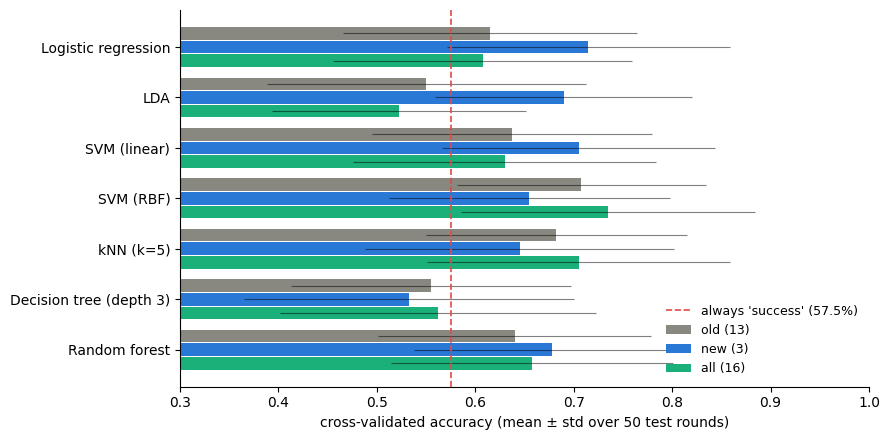

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
names = list(MODELS)[1:]
pos = np.arange(len(names))
for i, (fs, c) in enumerate(zip(FEATURE_SETS, ["#888780", "#2a78d6", "#1baf7a"])):
    vals = [results.query("features == @fs and model == @m").accuracy.item() for m in names]
    errs = [results.query("features == @fs and model == @m").acc_std.item() for m in names]
    ax.barh(pos + (i - 1) * 0.27, vals, height=0.25, xerr=errs, color=c, label=fs, error_kw=dict(lw=0.8, alpha=0.5))
ax.axvline(y.mean(), color="#e34948", ls="--", lw=1.2, label="always 'success' (57.5%)")
ax.set_yticks(pos); ax.set_yticklabels(names); ax.invert_yaxis()
ax.set_xlabel("cross-validated accuracy (mean ± std over 50 test rounds)"); ax.set_xlim(0.3, 1.0)
ax.legend(loc="lower right", fontsize=9, frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [7]:
results.sort_values("accuracy", ascending=False).head(8).round(3).reset_index(drop=True)

,features,model,accuracy,balanced_accuracy,f1,roc_auc,acc_std
0,all (16),SVM (RBF),0.735,0.725,0.776,0.728,0.149
1,new (3),Logistic regression,0.715,0.700,0.756,0.763,0.144
2,old (13),SVM (RBF),0.708,0.700,0.760,0.736,0.127
3,all (16),kNN (k=5),0.705,0.688,0.758,0.705,0.154
4,new (3),SVM (linear),0.705,0.685,0.757,0.751,0.139
5,new (3),LDA,0.690,0.678,0.732,0.743,0.130
6,old (13),kNN (k=5),0.682,0.674,0.729,0.691,0.133
7,new (3),Random forest,0.678,0.663,0.716,0.734,0.139


## 4. Honest estimate with nested cross-validation

The numbers above have a weakness: we picked the 3 new features and the model settings by looking at these same 40 episodes, so they are probably a bit optimistic.

**Nested CV** fixes this. The *inner* loop chooses the settings (how many features to keep, the C or k value) using only the training folds. The *outer* loop tests that whole choosing procedure on folds it never saw. The outer score is the honest number to report.

In [8]:
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE + 1)

def selecting(model):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("select", SelectKBest(f_classif)), ("model", model)])

SEARCH = {
    "Logistic regression": (selecting(LogisticRegression(max_iter=5000)),
                            {"select__k": [3, 5, 8, "all"], "model__C": [0.1, 0.3, 1.0]}),
    "SVM (RBF)":           (selecting(SVC(kernel="rbf")),
                            {"select__k": [3, 5, 8, "all"], "model__C": [0.3, 1.0, 3.0]}),
    "kNN":                 (selecting(KNeighborsClassifier()),
                            {"select__k": [3, 5, 8, "all"], "model__n_neighbors": [3, 5, 7, 9]}),
}
nested = []
for name, (p, grid) in SEARCH.items():
    gs = GridSearchCV(p, grid, cv=inner, scoring="accuracy")
    s = cross_validate(gs, X_all, y, cv=outer, scoring=["accuracy", "f1", "roc_auc"])
    nested.append({"model": name, "nested accuracy": s["test_accuracy"].mean(), "std": s["test_accuracy"].std(),
                   "f1": s["test_f1"].mean(), "roc_auc": s["test_roc_auc"].mean()})
pd.DataFrame(nested).round(3)

,model,nested accuracy,std,f1,roc_auc
0,Logistic regression,0.665,0.104,0.729,0.694
1,SVM (RBF),0.655,0.138,0.702,0.728
2,kNN,0.705,0.145,0.750,0.718


## 5. Which mistakes does the best simple model make?

              precision    recall  f1-score   support

        fail      0.667     0.588     0.625        17
     success      0.720     0.783     0.750        23

    accuracy                          0.700        40
   macro avg      0.693     0.685     0.688        40
weighted avg      0.697     0.700     0.697        40



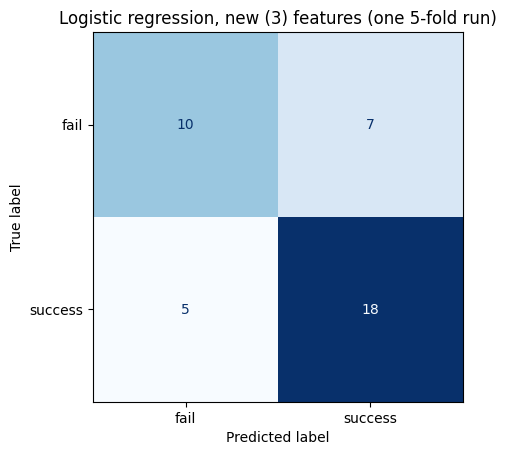

In [9]:
BEST_SET, BEST_MODEL = "new (3)", "Logistic regression"
best = MODELS[BEST_MODEL]
cols = FEATURE_SETS[BEST_SET]
pred = cross_val_predict(best, X_all[cols], y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
print(classification_report(y, pred, target_names=["fail", "success"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["fail", "success"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{BEST_MODEL}, {BEST_SET} features (one 5-fold run)"); plt.show()

In [10]:
wrong = table.loc[pred != y, ["episode", "label"]].assign(predicted=pred[pred != y])
wrong

,episode,label,predicted
0,000002,1,0
1,000009,1,0
2,000016,1,0
7,000024,1,0
18,000041,1,0
33,000021,0,1
34,000025,0,1
35,000028,0,1
36,000035,0,1
37,000044,0,1


## 6. Which clues matter? (for Wafi's score)

**Permutation importance:** shuffle one feature at a time and measure how much accuracy drops. A big drop means the model relies on that feature. Measured on the "all" feature set with logistic regression, averaged over the cross-validation folds.

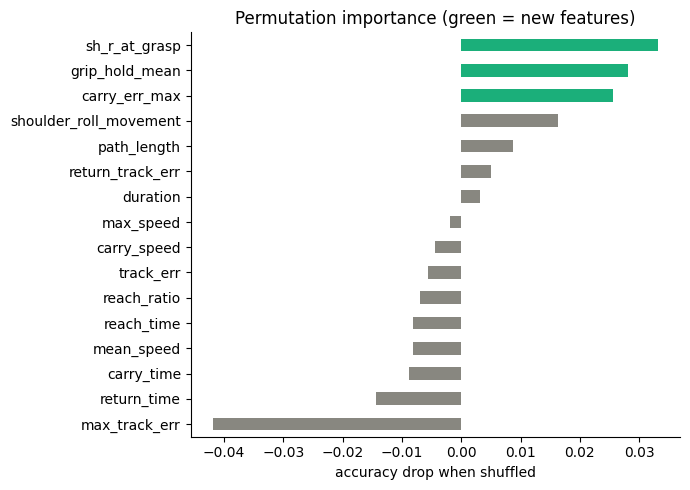

,importance,logreg coef (+ = more success)
sh_r_at_grasp,0.033,0.318
grip_hold_mean,0.028,-0.345
carry_err_max,0.026,0.371
shoulder_roll_movement,0.016,0.307
path_length,0.009,-0.043
return_track_err,0.005,0.294
duration,0.003,0.039
max_speed,-0.002,0.169
carry_speed,-0.004,-0.023
track_err,-0.006,0.045


In [11]:
imp = []
cols = FEATURE_SETS["all (16)"]
m = MODELS["Logistic regression"]
for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE).split(X_all, y):
    m.fit(X_all.iloc[tr][cols], y[tr])
    r = permutation_importance(m, X_all.iloc[te][cols], y[te], n_repeats=10, random_state=RANDOM_STATE)
    imp.append(r.importances_mean)
imp = pd.Series(np.mean(imp, axis=0), index=cols).sort_values()
m.fit(X_all[cols], y)
coef = pd.Series(m.named_steps["model"].coef_[0], index=cols)
ax = imp.plot.barh(figsize=(7, 5), color=["#1baf7a" if c in NEW else "#888780" for c in imp.index])
ax.set_xlabel("accuracy drop when shuffled"); ax.set_title("Permutation importance (green = new features)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
pd.DataFrame({"importance": imp, "logreg coef (+ = more success)": coef}).sort_values("importance", ascending=False).round(3)

## 7. Caution: outcome drifts with recording order

Early episodes failed much more often than later ones. If a feature also changes steadily over the recording session, part of what it detects may be "the setup changed over time" rather than the physical cause of tipping. That matters if demo-day data was recorded at a different time.

In [12]:
num = table.episode.astype(int)
drift = pd.DataFrame({"feature": NEW + ["label"],
                      "spearman rho with episode number": [pd.Series(table[c]).corr(num, method="spearman") for c in NEW + ["label"]]})
drift.round(2)

,feature,spearman rho with episode number
0,grip_hold_mean,-0.56
1,sh_r_at_grasp,0.66
2,carry_err_max,0.56
3,label,0.34


In [13]:
# How far does recording order ALONE get us? (NOT a usable feature: demo-day files have their own numbering)
from sklearn.model_selection import cross_val_score
from scipy.stats import mannwhitneyu
lr = pipe(LogisticRegression(C=0.3, max_iter=5000))
print("episode number as the only input:", round(cross_val_score(lr, num.to_frame(), y, cv=CV).mean(), 3))
print("3 new features:                  ", round(cross_val_score(lr, X_all[NEW], y, cv=CV).mean(), 3))
print("success rate, episodes 1-24:", y[num <= 24].mean().round(2), "| episodes 25-48:", y[num > 24].mean().round(2))
for c in NEW:
    resid = table[c] - np.poly1d(np.polyfit(num, table[c], 1))(num)   # remove the straight-line time trend
    print(f"{c:15s} still separates success/fail after removing the time trend? p = {mannwhitneyu(resid[y == 1], resid[y == 0]).pvalue:.3f}")

episode number as the only input: 0.702


3 new features:                   0.715
success rate, episodes 1-24: 0.42 | episodes 25-48: 0.71
grip_hold_mean  still separates success/fail after removing the time trend? p = 0.428
sh_r_at_grasp   still separates success/fail after removing the time trend? p = 0.101
carry_err_max   still separates success/fail after removing the time trend? p = 0.113


## 8. Conclusions

1. **Best plain cross-validated accuracy is about 0.70–0.74** (SVM-RBF on all 16 features: 0.735; logistic regression on the 3 new features: 0.715), against a 0.575 baseline. Spread across folds is large (±0.14), as expected with 40 episodes.
2. **The honest (nested CV) estimate is lower: about 0.66–0.70.** That is the number to report: it accounts for choosing features and settings on the same data.
3. **The 3 new features beat the 13 old ones** for the linear models (logistic regression 0.62 → 0.72). Permutation importance ranks them as the 3 most useful clues. Decision trees do badly (0.53–0.56): too few episodes for them.
4. **Main caveat: the result drifts with recording order.** Early episodes fail far more often than later ones (42% vs 71% success). The episode number on its own reaches about 0.70, the same as our features. After removing the time trend, the new features no longer separate the classes clearly. The misclassified episodes also follow this pattern: late fails get predicted as success, and early successes as fail.
   **So the current features largely detect "early vs late in the session" rather than the physical cause of tipping.** That could fail on demo-day data recorded at another time.

**Next steps**
- Ask Mr. Yong / the TA: were the episodes recorded in this order, and did anything change during the session (bottle position, robot calibration, operator, control policy)?
- Look for clues that separate success and fail **within** the same period (compare early fails with early successes, and late fails with late successes).
- Until then, prefer simple, regularised models (logistic regression / linear SVM), and report the nested-CV number.